# Домашнее задание 1. Message passing своими руками

**ФИО:** Ишутин Клим Владимирович  
**Группа:** S4202

Выполнены все части задания:

- реализация и проверка MyGCNConv и MySAGEConv;
- эксперименты на Cora и CiteSeer;
- сравнение с MLP;
- проверка моделей глубиной 2, 4, 8 и 16 слоев;
- inductive и transductive режимы GraphSAGE;
- сравнение GCN и MLP при разной доле разметки.

In [ ]:
%pip install -q torch-geometric pytest pandas matplotlib

In [ ]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.data import Data
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import add_self_loops, degree, subgraph, to_undirected

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Устройство: cpu


(в коллабе проблема с гпу последние дни)

## 1. Собственные слои

В GCN к графу добавляются петли, после чего сообщения нормируются степенями отправителя и получателя. В GraphSAGE петли не нужны: среднее по соседям и собственный вектор проходят через разные матрицы.

In [ ]:
%%writefile submission.py
import torch
from torch import nn
from torch_geometric.utils import add_self_loops, degree


class MyGCNConv(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin = nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, x, edge_index):
        num_nodes = x.size(0)
        edge_index, _ = add_self_loops(edge_index, num_nodes=num_nodes)
        source, target = edge_index

        deg = degree(target, num_nodes, dtype=x.dtype).clamp(min=1)
        norm = deg[source].pow(-0.5) * deg[target].pow(-0.5)

        messages = self.lin(x)[source] * norm.unsqueeze(-1)
        out = x.new_zeros((num_nodes, self.lin.out_features))
        out.index_add_(0, target, messages)
        return out


class MySAGEConv(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin_neigh = nn.Linear(in_dim, out_dim, bias=False)
        self.lin_self = nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, x, edge_index):
        num_nodes = x.size(0)
        source, target = edge_index

        neigh_sum = torch.zeros_like(x)
        neigh_sum.index_add_(0, target, x[source])
        deg = degree(target, num_nodes, dtype=x.dtype).clamp(min=1)
        neigh_mean = neigh_sum / deg.unsqueeze(-1)

        return self.lin_neigh(neigh_mean) + self.lin_self(x)

Writing submission.py


In [ ]:
from submission import MyGCNConv, MySAGEConv

!wget -q https://raw.githubusercontent.com/rustam-azimov/gnn-course-itmo/main/tasks/tests/test_task1.py -O test_task1.py
!pytest test_task1.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collecting ... 


collecting 7 items                                                             
collected 7 items                                                              

test_task1.py::test_gcn_output_shape 

PASSED                              [ 14%]
test_task1.py::test_gcn_matches_pyg PASSED                               [ 28%]
test_task1.py::test_gcn_on_directed_graph PASSED                         [ 42%]
test_task1.py::test_gcn_permutation_invariance PASSED                    [ 57%]
test_task1.py::test_gcn_isolated_node_is_finite PASSED                   [ 71%]
test_task1.py::test_sage_matches_pyg PASSED                              [ 85%]
test_task1.py::test_gcn_is_trainable PASSED                              [100%]

============================== 7 passed in 8.29s ===============================


## 2. Данные и модели

Используется стандартный публичный сплит Planetoid. Во время обучения модель получает весь граф, но функция потерь считается только на вершинах из train_mask.

In [ ]:
graphs = {}

for name in ["Cora", "CiteSeer"]:
    dataset = Planetoid(root=f"data/{name}", name=name)
    data = dataset[0]
    data.edge_index = to_undirected(data.edge_index)
    graphs[name] = (dataset, data.to(device))
    print(
        name,
        f"вершин: {data.num_nodes},",
        f"признаков: {dataset.num_features},",
        f"классов: {dataset.num_classes}"
    )

Processing...


Done!


Cora вершин: 2708, признаков: 1433, классов: 7


Processing...


CiteSeer вершин: 3327, признаков: 3703, классов: 6


Done!


In [ ]:
class GNN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, conv, layers=2, dropout=0.5):
        super().__init__()
        dims = [in_dim] + [hidden_dim] * (layers - 1) + [out_dim]
        self.convs = nn.ModuleList([conv(dims[i], dims[i + 1]) for i in range(layers)])
        self.dropout = dropout

    def forward(self, x, edge_index, return_hidden=False):
        hidden = None
        for i, conv in enumerate(self.convs):
            x = conv(x, edge_index)
            if i < len(self.convs) - 1:
                x = F.relu(x)
                hidden = x
                x = F.dropout(x, p=self.dropout, training=self.training)
        return (x, hidden) if return_hidden else x


class MLP(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, layers=2, dropout=0.5):
        super().__init__()
        dims = [in_dim] + [hidden_dim] * (layers - 1) + [out_dim]
        self.layers = nn.ModuleList([nn.Linear(dims[i], dims[i + 1]) for i in range(layers)])
        self.dropout = dropout

    def forward(self, x, edge_index=None, return_hidden=False):
        hidden = None
        for i, layer in enumerate(self.layers):
            x = layer(x)
            if i < len(self.layers) - 1:
                x = F.relu(x)
                hidden = x
                x = F.dropout(x, p=self.dropout, training=self.training)
        return (x, hidden) if return_hidden else x

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_model(
    model, data, epochs=300, patience=40, lr=0.01, weight_decay=5e-4,
    eval_data=None, eval_mask=None
):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val = -1.0
    best_state = None
    waiting = 0

    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits = model(data.x, data.edge_index)
        loss = F.cross_entropy(logits[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            pred = model(data.x, data.edge_index).argmax(dim=1)
            val_acc = (pred[data.val_mask] == data.y[data.val_mask]).float().mean().item()

        if val_acc > best_val:
            best_val = val_acc
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            waiting = 0
        else:
            waiting += 1
            if waiting >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    eval_data = data if eval_data is None else eval_data
    eval_mask = eval_data.test_mask if eval_mask is None else eval_mask
    with torch.no_grad():
        pred = model(eval_data.x, eval_data.edge_index).argmax(dim=1)
        test_acc = (pred[eval_mask] == eval_data.y[eval_mask]).float().mean().item()

    return test_acc, model


def run_seeds(make_model, data, seeds=range(5)):
    scores = []
    models = []
    for seed in seeds:
        set_seed(seed)
        score, model = train_model(make_model(), data)
        scores.append(score)
        models.append(model)
        print(f"seed {seed}: {score:.4f}")
    return scores, models

## 3. Cora и CiteSeer

Для каждой модели используется пять сидов. Размер скрытого слоя и остальные параметры одинаковы, поэтому MLP отличается только тем, что не использует ребра.

In [ ]:
hidden_dim = 64
experiment_rows = []

for dataset_name, (dataset, data) in graphs.items():
    model_factories = {
        "GCN": lambda: GNN(dataset.num_features, hidden_dim, dataset.num_classes, MyGCNConv),
        "GraphSAGE": lambda: GNN(dataset.num_features, hidden_dim, dataset.num_classes, MySAGEConv),
        "MLP": lambda: MLP(dataset.num_features, hidden_dim, dataset.num_classes),
    }

    for model_name, make_model in model_factories.items():
        print(f"\n{dataset_name}, {model_name}")
        scores, _ = run_seeds(make_model, data)
        experiment_rows.append({
            "dataset": dataset_name,
            "model": model_name,
            "mean": np.mean(scores),
            "std": np.std(scores, ddof=1),
            "runs": scores,
        })

results = pd.DataFrame(experiment_rows)
results[["dataset", "model", "mean", "std"]]


Cora, GCN


seed 0: 0.7950


seed 1: 0.8060


seed 2: 0.7980


seed 3: 0.7980


seed 4: 0.7920

Cora, GraphSAGE


... (22 outputs left out)

seed 2: 0.5740


seed 3: 0.5880


seed 4: 0.5420


,dataset,model,mean,std
0,Cora,GCN,0.7978,0.005215
1,Cora,GraphSAGE,0.7900,0.005788
2,Cora,MLP,0.5676,0.006309
3,CiteSeer,GCN,0.6872,0.004207
4,CiteSeer,GraphSAGE,0.6826,0.022930
5,CiteSeer,MLP,0.5622,0.021845


In [ ]:
paper_scores = {"Cora": 0.815, "CiteSeer": 0.703}
comparison_rows = []

for dataset_name in paper_scores:
    subset = results[results.dataset == dataset_name].set_index("model")
    gcn_score = subset.loc["GCN", "mean"]
    mlp_score = subset.loc["MLP", "mean"]
    comparison_rows.append({
        "dataset": dataset_name,
        "GCN": gcn_score,
        "статья": paper_scores[dataset_name],
        "разница со статьей": gcn_score - paper_scores[dataset_name],
        "прирост над MLP": gcn_score - mlp_score,
        "попадание в 2 п.п.": abs(gcn_score - paper_scores[dataset_name]) <= 0.02,
    })

comparison = pd.DataFrame(comparison_rows)
comparison

,dataset,GCN,статья,разница со статьей,прирост над MLP,попадание в 2 п.п.
0,Cora,0.7978,0.815,-0.0172,0.2302,True
1,CiteSeer,0.6872,0.703,-0.0158,0.1250,True


GCN попал в допустимый диапазон для обоих датасетов. На Cora получилось 0.7978 ± 0.0052 против 0.815 в статье, на CiteSeer 0.6872 ± 0.0042 против 0.703. Граф особенно полезен на Cora: преимущество над MLP составило 0.2302. На CiteSeer прирост тоже заметный и равен 0.1250. GraphSAGE показал близкий результат, но на CiteSeer разброс между запусками оказался выше.

## 4. Что происходит при увеличении глубины

Эксперимент проводится на Cora. Кроме accuracy измеряется среднее косинусное сходство между представлениями разных вершин. Дополнительно считается доля почти нулевых представлений, чтобы не перепутать oversmoothing с неудачным обучением.

In [ ]:
def mean_cosine_similarity(hidden):
    normalized = F.normalize(hidden, dim=1)
    similarities = normalized @ normalized.T
    n = similarities.size(0)
    return ((similarities.sum() - similarities.diag().sum()) / (n * (n - 1))).item()


def dead_node_fraction(hidden, eps=1e-8):
    return (hidden.norm(dim=1) < eps).float().mean().item()


dataset, cora = graphs["Cora"]
depth_rows = []

for depth in [2, 4, 8, 16]:
    for seed in range(5):
        set_seed(seed)
        model = GNN(
            dataset.num_features, hidden_dim, dataset.num_classes,
            MyGCNConv, layers=depth
        )
        accuracy, model = train_model(model, cora)

        with torch.no_grad():
            _, hidden = model(cora.x, cora.edge_index, return_hidden=True)

        depth_rows.append({
            "depth": depth,
            "seed": seed,
            "accuracy": accuracy,
            "similarity": mean_cosine_similarity(hidden),
            "dead_fraction": dead_node_fraction(hidden),
        })
        print(f"слоев {depth:2d}, seed {seed}: accuracy {accuracy:.4f}")

depth_results = pd.DataFrame(depth_rows)
depth_summary = depth_results.groupby("depth").agg(
    accuracy_mean=("accuracy", "mean"),
    accuracy_std=("accuracy", "std"),
    similarity_mean=("similarity", "mean"),
    similarity_std=("similarity", "std"),
    dead_fraction=("dead_fraction", "mean"),
).reset_index()
depth_summary

слоев  2, seed 0: accuracy 0.7950


слоев  2, seed 1: accuracy 0.8060


слоев  2, seed 2: accuracy 0.7980


слоев  2, seed 3: accuracy 0.7980


слоев  2, seed 4: accuracy 0.7920


слоев  4, seed 0: accuracy 0.7780


... (11 outputs left out)

слоев 16, seed 2: accuracy 0.3220


слоев 16, seed 3: accuracy 0.3190


слоев 16, seed 4: accuracy 0.3030


,depth,accuracy_mean,accuracy_std,similarity_mean,similarity_std,dead_fraction
0,2,0.7978,0.005215,0.743224,0.016204,0.000000
1,4,0.7854,0.008562,0.578892,0.041791,0.000000
2,8,0.2856,0.078643,0.739545,0.413579,0.531241
3,16,0.3162,0.007530,0.394693,0.540462,0.800000


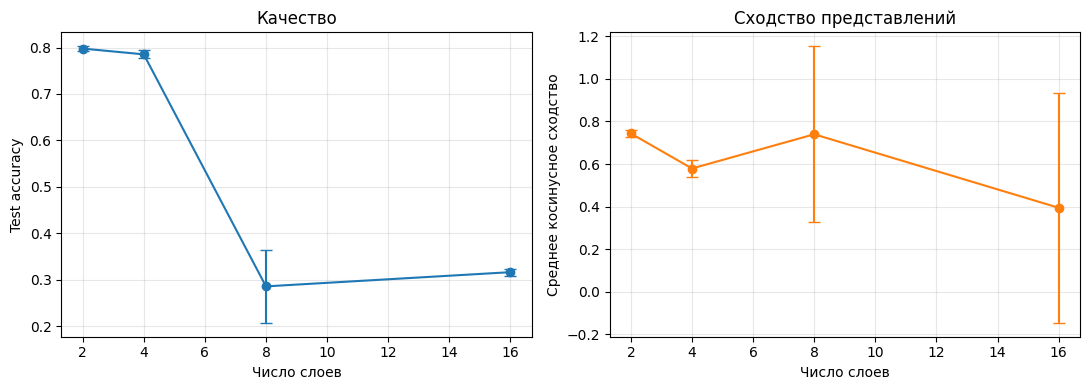

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].errorbar(
    depth_summary.depth, depth_summary.accuracy_mean,
    yerr=depth_summary.accuracy_std, marker="o", capsize=4
)
axes[0].set_xlabel("Число слоев")
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Качество")
axes[0].grid(alpha=0.3)

axes[1].errorbar(
    depth_summary.depth, depth_summary.similarity_mean,
    yerr=depth_summary.similarity_std, marker="o", capsize=4, color="tab:orange"
)
axes[1].set_xlabel("Число слоев")
axes[1].set_ylabel("Среднее косинусное сходство")
axes[1].set_title("Сходство представлений")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

При переходе от 2 к 4 слоям accuracy немного снизилась, но представления не стали более похожими. У 8 и 16 слоев качество резко упало до 0.2856 и 0.3162. При этом среднее сходство не стремится к единице и имеет большой разброс между сидами. Главная причина видна по доле нулевых представлений: 0.53 для 8 слоев и 0.80 для 16. Значит, здесь наблюдается не чистый oversmoothing. Значительная часть активаций занулилась, и глубокая сеть фактически не смогла нормально обучиться.

## 5. Бонус A. Inductive-режим

В inductive-режиме тестовые вершины Cora и все связанные с ними ребра удаляются из графа на время обучения. После обучения GraphSAGE применяется к полному графу. Для сравнения в transductive-режиме модель видит весь граф, но функция потерь по-прежнему считается только на обучающих вершинах.

In [ ]:
cora_dataset, cora = graphs["Cora"]
kept_nodes = (~cora.test_mask).nonzero(as_tuple=False).view(-1)
train_edges, _ = subgraph(
    kept_nodes, cora.edge_index, relabel_nodes=True, num_nodes=cora.num_nodes
)

train_cora = Data(
    x=cora.x[kept_nodes],
    y=cora.y[kept_nodes],
    edge_index=train_edges,
    train_mask=cora.train_mask[kept_nodes],
    val_mask=cora.val_mask[kept_nodes],
).to(device)

print("Полный граф:", cora.num_nodes, "вершин и", cora.num_edges, "ребер")
print("Граф для inductive-обучения:", train_cora.num_nodes, "вершин и", train_cora.num_edges, "ребер")

Полный граф: 2708 вершин и 10556 ребер
Граф для inductive-обучения: 1708 вершин и 4438 ребер


In [ ]:
inductive_rows = []

for mode in ["inductive", "transductive"]:
    for seed in range(5):
        set_seed(seed)
        model = GNN(
            cora_dataset.num_features, hidden_dim, cora_dataset.num_classes, MySAGEConv
        )

        if mode == "inductive":
            score, model = train_model(
                model, train_cora, eval_data=cora, eval_mask=cora.test_mask
            )
        else:
            score, model = train_model(model, cora)

        inductive_rows.append({"mode": mode, "seed": seed, "accuracy": score})
        print(f"{mode:12s}, seed {seed}: {score:.4f}")

inductive_results = pd.DataFrame(inductive_rows)
inductive_summary = inductive_results.groupby("mode").accuracy.agg(["mean", "std"])
inductive_summary

inductive   , seed 0: 0.7960


inductive   , seed 1: 0.7640


inductive   , seed 2: 0.7940


inductive   , seed 3: 0.7740


inductive   , seed 4: 0.7870


transductive, seed 0: 0.7860


transductive, seed 1: 0.7910


transductive, seed 2: 0.7840


transductive, seed 3: 0.7900


transductive, seed 4: 0.7990


,mean,std
mode,,
inductive,0.783,0.013675
transductive,0.790,0.005788


| Режим | Видела ли модель новые вершины при обучении? | Accuracy на новых вершинах |
|---|---|---:|
| inductive | нет | 0.7830 ± 0.0137 |
| transductive | да, но без меток | 0.7900 ± 0.0058 |

Цена inductive-режима оказалась небольшой: среднее качество снизилось на 0.007. GraphSAGE умеет применить общие правила агрегации к новым вершинам. Небольшая разница возникает из-за того, что при обучении модель не использовала тестовые вершины и их связи.

## 6. Бонус B. Сколько разметки нужно графу

Стандартные validation и test множества остаются неизменными. Доля разметки считается среди остальных вершин. Для каждой доли и каждого сида обучающие вершины выбираются отдельно внутри каждого класса, чтобы при малой доле не потерять редкие классы.

In [ ]:
def sample_train_mask(data, fraction, seed):
    generator = torch.Generator().manual_seed(seed)
    labels = data.y.cpu()
    pool = (~(data.val_mask | data.test_mask)).cpu()
    mask = torch.zeros(data.num_nodes, dtype=torch.bool)

    for class_id in range(int(data.y.max()) + 1):
        nodes = torch.where(pool & (labels == class_id))[0]
        count = max(1, round(nodes.numel() * fraction))
        chosen = nodes[torch.randperm(nodes.numel(), generator=generator)[:count]]
        mask[chosen] = True

    return mask.to(data.x.device)


label_rows = []
fractions = [0.01, 0.05, 0.20, 0.60]

for fraction in fractions:
    for seed in range(5):
        sampled_cora = cora.clone()
        sampled_cora.train_mask = sample_train_mask(cora, fraction, seed)

        factories = {
            "GCN": lambda: GNN(
                cora_dataset.num_features, hidden_dim, cora_dataset.num_classes, MyGCNConv
            ),
            "MLP": lambda: MLP(
                cora_dataset.num_features, hidden_dim, cora_dataset.num_classes
            ),
        }

        for model_name, make_model in factories.items():
            set_seed(seed)
            score, _ = train_model(make_model(), sampled_cora)
            label_rows.append({
                "fraction": fraction,
                "seed": seed,
                "model": model_name,
                "accuracy": score,
                "labeled_nodes": int(sampled_cora.train_mask.sum()),
            })
            print(f"{fraction:4.0%}, {model_name:3s}, seed {seed}: {score:.4f}")

label_results = pd.DataFrame(label_rows)
label_summary = label_results.groupby(["fraction", "model"]).agg(
    accuracy_mean=("accuracy", "mean"),
    accuracy_std=("accuracy", "std"),
    labeled_nodes=("labeled_nodes", "first"),
).reset_index()
label_summary

  1%, GCN, seed 0: 0.5350


  1%, MLP, seed 0: 0.3250


  1%, GCN, seed 1: 0.5210


  1%, MLP, seed 1: 0.3460


  1%, GCN, seed 2: 0.6840


  1%, MLP, seed 2: 0.4070


... (31 outputs left out)

 60%, MLP, seed 3: 0.7330


 60%, GCN, seed 4: 0.8700


 60%, MLP, seed 4: 0.7270


,fraction,model,accuracy_mean,accuracy_std,labeled_nodes
0,0.01,GCN,0.5882,0.064975,12
1,0.01,MLP,0.3682,0.033656,12
2,0.05,GCN,0.7770,0.019170,60
3,0.05,MLP,0.5230,0.026125,60
4,0.20,GCN,0.8264,0.013483,241
5,0.20,MLP,0.6372,0.014721,241
6,0.60,GCN,0.8670,0.003873,726
7,0.60,MLP,0.7234,0.006656,726


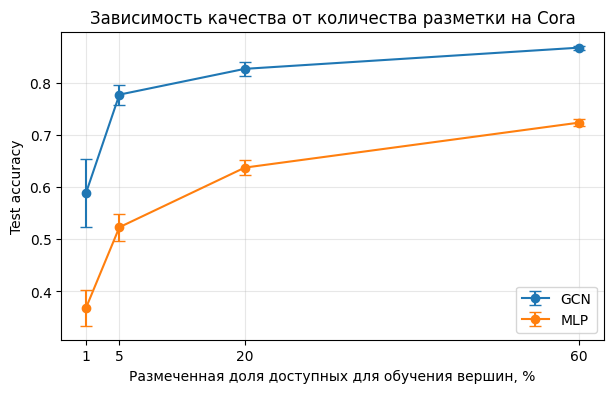

In [ ]:
plt.figure(figsize=(7, 4))

for model_name, color in [("GCN", "tab:blue"), ("MLP", "tab:orange")]:
    part = label_summary[label_summary.model == model_name]
    plt.errorbar(
        part.fraction * 100, part.accuracy_mean, yerr=part.accuracy_std,
        marker="o", capsize=4, label=model_name, color=color
    )

plt.xlabel("Размеченная доля доступных для обучения вершин, %")
plt.ylabel("Test accuracy")
plt.title("Зависимость качества от количества разметки на Cora")
plt.xticks([1, 5, 20, 60])
plt.grid(alpha=0.3)
plt.legend()
plt.show()

GCN оказался лучше MLP при каждой проверенной доле разметки. При 1% разница составила 0.2200, при 5% 0.2540, при 20% 0.1892, при 60% 0.1436. В исследованном диапазоне преимущество графа не исчезло, хотя при большом количестве меток оно стало меньше. MLP получает больше прямых примеров каждого класса, но GCN по-прежнему использует дополнительную информацию о связях между статьями.